# UsahaCerdas: Baseline ML (Fase Implementation)

Notebook ini menjalankan seluruh alur baseline secara berurutan dan bisa diulang (seed 42):

1. **Dataset sintetis** transaksi 4 UMKM selama 18 bulan (`ml/src/generate_dataset.py`).
2. **Kategorisasi transaksi**: keterangan -> kategori dengan TF-IDF + Logistic Regression (`ml/src/train_categorizer.py`).
3. **Prediksi arus kas** 30 hari ke depan per usaha (`ml/src/forecast_baseline.py`).

Kategori mengikuti 6 kategori bawaan aplikasi UsahaCerdas, sehingga model bisa dipasang ke aplikasi nanti.

In [1]:
import os, json
from pathlib import Path
# Jalankan dari root repo agar path ml/... konsisten
while not Path('ml/src').exists():
    os.chdir('..')
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option('display.max_colwidth', 80)
print('cwd:', os.getcwd())

cwd: E:\coding\project ml\UsahaCerdas


## 1. Dataset sintetis

In [2]:
!python ml/src/generate_dataset.py --out ml/data/transactions.csv --seed 42
df = pd.read_csv('ml/data/transactions.csv', parse_dates=['date'])
df.sample(8, random_state=3)[['business_type', 'date', 'type', 'category', 'amount', 'note']]

11,778 transaksi, 4 usaha, 2025-05-01 s.d. 2026-10-31 -> ml\data\transactions.csv
category
Penjualan          8612
Transportasi       1249
Bahan Baku         1158
Operasional         420
Pendapatan Lain     248
Lain-lain            91


,business_type,date,type,category,amount,note
2499,fashion,2026-07-21,EXPENSE,Bahan Baku,2055500,Kulakan dari toko kian cigondewah
5117,kelontong,2026-05-22,EXPENSE,Transportasi,24000,sewa pickup angkut mie instan
10382,laundry,2026-01-27,EXPENSE,Transportasi,28000,grab ke toko kimia Sentosa
8077,kuliner,2026-05-12,INCOME,Penjualan,189500,DP PESANAN ES KOPI GULA AREN BU TINI
455,fashion,2025-07-21,INCOME,Penjualan,642000,pesanan tiktok shop tunik
7413,kuliner,2026-01-14,INCOME,Penjualan,43000,omzet isang
6649,kuliner,2025-08-26,EXPENSE,Transportasi,25000,sewa pickup angkut minyak goreng
6264,kuliner,2025-06-16,EXPENSE,Bahan Baku,1121000,Bayar nota toko sinar jaya tf bca


Catatan desain data:
- Keterangan ditulis dari 64 pola kalimat (template) dengan variasi singkatan, salah ketik, dan huruf kapital.
- 2% label sengaja dibuat salah (kolom `category`) untuk meniru salah pilih kategori saat input manual. Label sebenarnya disimpan di `true_category` dan dipakai saat evaluasi.
- Kelas sangat tidak seimbang, seperti data asli: penjualan jauh lebih sering dicatat.

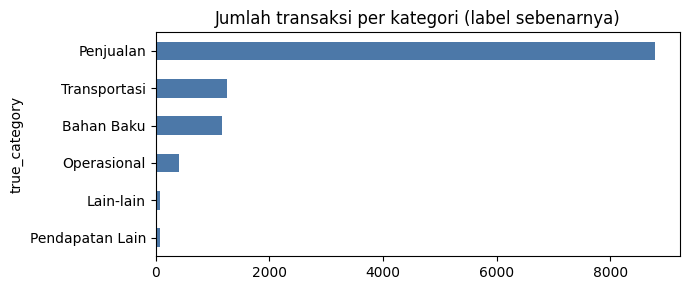

Label yang dibuat salah: 236 baris


In [3]:
counts = df['true_category'].value_counts()
ax = counts.plot.barh(figsize=(7, 3), color='#4C78A8', title='Jumlah transaksi per kategori (label sebenarnya)')
ax.invert_yaxis(); plt.tight_layout(); plt.show()
print('Label yang dibuat salah:', (df['category'] != df['true_category']).sum(), 'baris')

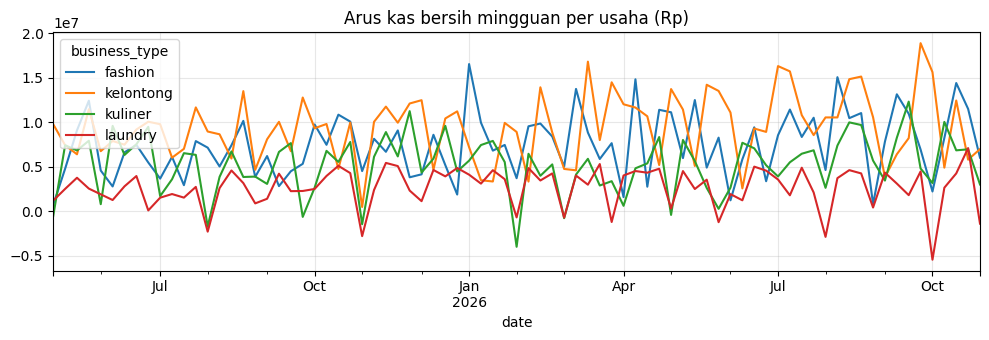

In [4]:
import numpy as np
net = df.assign(signed=np.where(df.type == 'INCOME', df.amount, -df.amount)).groupby(['business_type', pd.Grouper(key='date', freq='W')])['signed'].sum().unstack(0)
net.plot(figsize=(10, 3.5), title='Arus kas bersih mingguan per usaha (Rp)'); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## 2. Kategorisasi transaksi

In [5]:
!python ml/src/train_categorizer.py
m = json.load(open('ml/reports/categorizer_metrics.json', encoding='utf8'))
rows = []
for split in ['random_split', 'template_split']:
    r = m[split]
    rows.append({'skema': split, 'n_latih': r['n_train'], 'n_uji': r['n_test'],
                 'dummy macro-F1': round(r['dummy']['macro_f1'], 3),
                 'TF-IDF+LogReg akurasi': round(r['tfidf_logreg']['accuracy'], 3),
                 'TF-IDF+LogReg macro-F1': round(r['tfidf_logreg']['macro_f1'], 3),
                 'hiperparameter (GroupKFold)': r['chosen_params']})
pd.DataFrame(rows)

[random] latih=9,422 uji=2,356 | dummy macro-F1=0.142 | TF-IDF+LogReg acc=1.000 macro-F1=0.994 | dipilih {'clf__C': 1.0, 'clf__class_weight': None} (CV macro-F1 0.426)
[template] latih=8,979 uji=2,799 | dummy macro-F1=0.148 | TF-IDF+LogReg acc=0.932 macro-F1=0.513 | dipilih {'clf__C': 5.0, 'clf__class_weight': None} (CV macro-F1 0.359)
Model final (semua data) -> ml\models\categorizer.joblib


,skema,n_latih,n_uji,dummy macro-F1,TF-IDF+LogReg akurasi,TF-IDF+LogReg macro-F1,hiperparameter (GroupKFold)
0,random_split,9422,2356,0.142,1.000,0.994,"{'clf__C': 1.0, 'clf__class_weight': None}"
1,template_split,8979,2799,0.148,0.932,0.513,"{'clf__C': 5.0, 'clf__class_weight': None}"


In [6]:
pc = m['template_split']['tfidf_logreg']['per_class']
pd.DataFrame({k: pc[k] for k in sorted(m['dataset']['class_counts'])}).T[['precision', 'recall', 'f1-score', 'support']].round(2)

,precision,recall,f1-score,support
Bahan Baku,0.69,0.96,0.80,233.0
Lain-lain,0.00,0.00,0.00,15.0
Operasional,0.58,0.75,0.66,61.0
Pendapatan Lain,0.00,0.00,0.00,13.0
Penjualan,0.99,1.00,1.00,2223.0
Transportasi,0.85,0.49,0.62,254.0


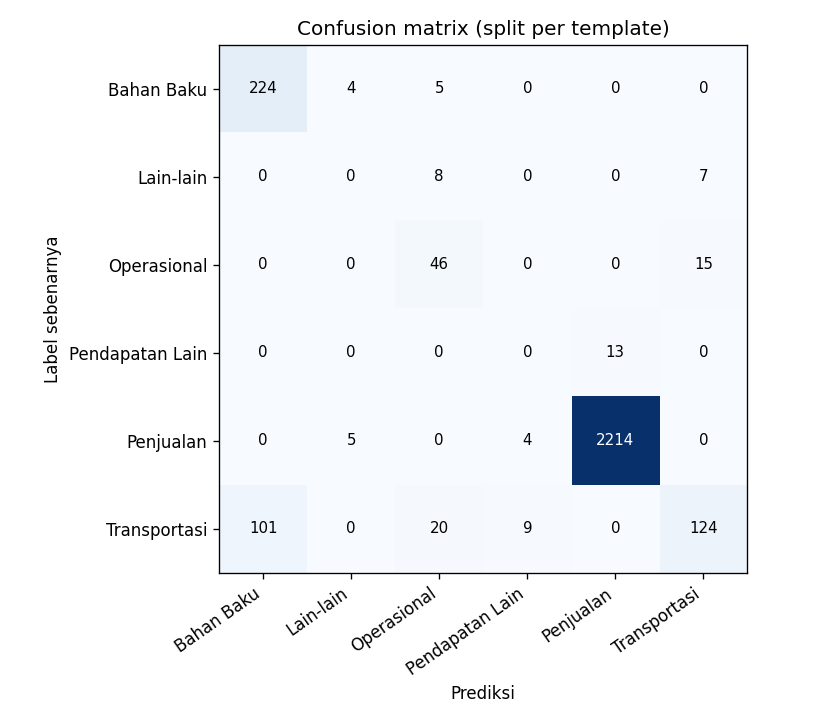

,note,true_category,pred
0,perbaikan atap bocor (cash),Lain-lain,Operasional
1,ongkir pos kirim gas elpiji,Transportasi,Bahan Baku
2,bunga tabungan bank,Pendapatan Lain,Penjualan
3,Ongkir gosend kirim minyak goreng,Transportasi,Pendapatan Lain
4,ONGKIR SICEPAT KIRIM ROKOK,Transportasi,Bahan Baku
5,transfer dari pelanggan Pak Budi untuk tunik,Penjualan,Lain-lain
6,transefr dari pelanggan Pak Budi untuk tunik,Penjualan,Lain-lain
7,ongkir pos kirim kaos oversize,Transportasi,Pendapatan Lain


In [7]:
display(Image('ml/reports/categorizer_confusion.png'))
pd.DataFrame(m['template_split']['sample_errors'])

**Interpretasi:**
- Split acak memberi skor hampir sempurna karena pola kalimat uji sudah pernah dilihat. Angka ini **tidak** mencerminkan pemakaian nyata.
- Split per template (pola kalimat baru) jauh lebih rendah. Penjualan dan Bahan Baku tetap baik, Transportasi sering tertukar dengan Bahan Baku (kalimat ongkir menyebut nama barang), sedangkan Pendapatan Lain dan Lain-lain gagal karena kalimatnya unik dan tidak berbagi kata dengan data latih.
- Kesimpulan: TF-IDF hanya mengenali kata yang pernah dilihat. Perlu data yang lebih beragam (data asli aplikasi) dan/atau representasi semantik (embedding/IndoBERT).

## 3. Prediksi arus kas 30 hari

In [8]:
!python ml/src/forecast_baseline.py
f = json.load(open('ml/reports/forecast_metrics.json', encoding='utf8'))
s = pd.DataFrame(f['summary']).set_index('method')
s['error total 30 hari (% rata-rata |aktual|)'] = (s['abs_err_30d_total'] / pd.DataFrame(f['folds'])['actual_30d_total'].abs().mean() * 100).round(1)
print('Origin evaluasi:', f['origins'])
s

Rata-rata |arus kas bersih harian|: Rp1,125,794
                 mae_daily  abs_err_30d_total
method                                       
gbm_calendar      968699.0          5885371.0
naive_mean       1023587.0          9135688.0
seasonal_weekly  1138629.0          9149203.0
method         gbm_calendar  naive_mean  seasonal_weekly
business_id                                             
biz-fashion       1166071.0   1185219.0        1302115.0
biz-kelontong     1289519.0   1273878.0        1366313.0
biz-kuliner        911276.0    990429.0        1118697.0
biz-laundry        507929.0    644822.0         767392.0
Origin evaluasi: ['2026-05-05', '2026-06-04', '2026-07-04', '2026-08-03', '2026-09-02', '2026-10-02']


,mae_daily,abs_err_30d_total,error total 30 hari (% rata-rata |aktual|)
method,,,
gbm_calendar,968699.0,5885371.0,20.1
naive_mean,1023587.0,9135688.0,31.2
seasonal_weekly,1138629.0,9149203.0,31.3


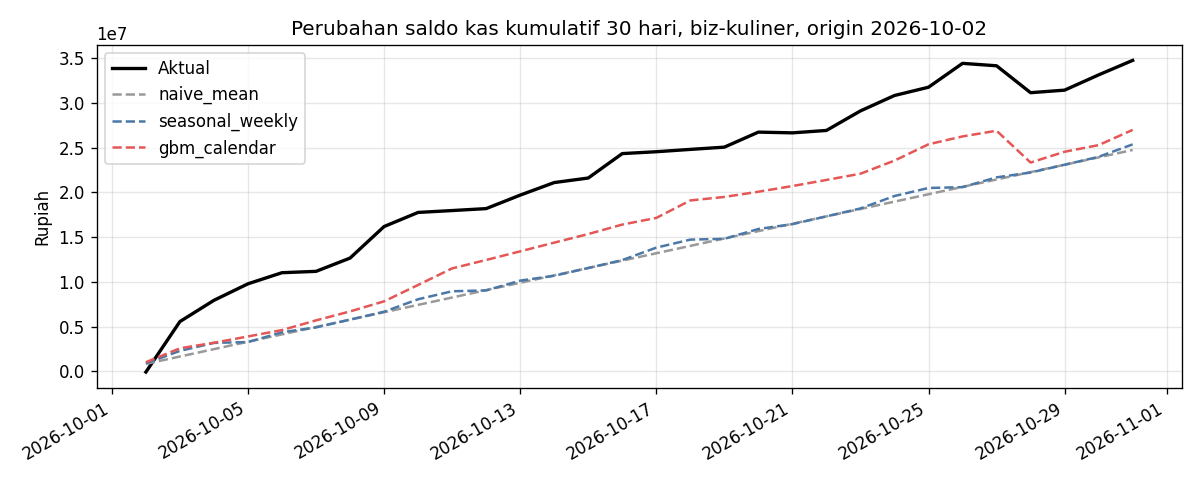

In [9]:
display(Image('ml/reports/forecast_example.png'))

**Interpretasi:**
- Model GBM dengan fitur kalender (tanggal gajian, tanggal bayar sewa/gaji, hari dalam minggu) paling baik, terutama untuk total 30 hari yang dipakai untuk peringatan kas menipis.
- Error harian masih besar karena pembelian bahan baku datang tidak teratur; untuk peringatan dini yang penting adalah total/saldo kumulatif.

## Langkah berikutnya
1. Menambah keragaman data: lebih banyak pola kalimat dan, bila tersedia, data asli dari aplikasi.
2. Mencoba representasi semantik (sentence embedding / IndoBERT) untuk kategori yang kalimatnya unik.
3. Integrasi: endpoint saran kategori di backend dan peringatan kas menipis di dashboard.